In [ ]:
import pathlib
from pathlib import Path
from tempfile import TemporaryDirectory

import marimo as mo
import pandas as pd

from cytodataframe.frame import CytoDataFrame

# CytoDataFrame in marimo

Inspect the same datasets and demonstrations as
`cytodataframe_at_a_glance.ipynb`: JUMP, NF1, nuclear speckles, the pediatric
cancer atlas, OME Parquet round trips, and 3D nuclei with and without masks.
The numbered sections follow all 26 display cells in the reference notebook.
No data downloads are needed after installing the environment.

From the repository root, open this notebook with:

```sh
uv run --with marimo==0.25.2 marimo edit docs/src/examples/marimo_and_cytodataframe.py
```

This example uses `mo.ui.dataframe` for native sorting, filtering, and
dataframe transformations. Original filenames and measurements remain in
the dataframe; adjacent preview columns use `format_mapping` to display
CytoDataFrame's image crops, composites, and 3D viewers. marimo controls
rebuild the viewer when their values change. The 3D sections use an
interactive browser renderer and save PyVista PNGs for GitHub. The
documentation snapshot shows the default values; changing the controls
requires the running marimo notebook.

In [ ]:
_location = mo.notebook_location() or Path.cwd()
_relative_data = Path("tests/data/cytotable/JUMP_plate_BR00117006")
_root = next(
    parent
    for parent in (_location, *_location.parents)
    if (parent / _relative_data).is_dir()
)
sample_dir = _root / _relative_data

In [ ]:
row_count = mo.ui.slider(1, 5, value=3, step=1, label="Cells", show_value=True)
brightness = mo.ui.slider(
    10, 90, value=50, step=10, label="Brightness", show_value=True
)
outlines = mo.ui.checkbox(value=False, label="Segmentation outlines")
composite = mo.ui.checkbox(value=False, label="DNA/RNA composite")
mo.hstack([row_count, brightness, outlines, composite], justify="start")

In [ ]:
jump_data_path = str(sample_dir)
nf1_cellpainting_path = str(sample_dir.parent / "NF1_cellpainting_data_shrunken")
nuclear_speckles_path = str(sample_dir.parent / "nuclear_speckles")
pediatric_cancer_atlas_path = str(
    sample_dir.parent / "pediatric_cancer_atlas_profiling"
)
cp_3d_path = str(sample_dir.parent.parent / "CP_tutorial_3D_noise_nuclei_segmentation")

In [ ]:
def render_frame(frame: CytoDataFrame) -> str:
    # marimo changes pandas display defaults. Keep the reference notebook's
    # limits so the 25-row texture example is not silently truncated.
    with pd.option_context("display.max_rows", 60, "display.max_columns", 0):
        if frame._find_3d_columns_for_display():
            return frame._generate_trame_snapshot_html()
        return frame._repr_html_(debug=True)

In [ ]:
static_3d = bool(mo.cli_args().get("static-3d")) if mo.running_in_notebook() else False

In [ ]:
# The generated Python cell wrapper combines these helper methods.
# ruff: noqa: C901, RUF100
from html import unescape
from html.parser import HTMLParser


class ImageCells(HTMLParser):
    """Read image cells without decoding or changing CytoDataFrame's pixels."""

    def __init__(self) -> None:
        super().__init__(convert_charrefs=False)
        self.columns = []
        self.rows = []
        self._header = False
        self._body = False
        self._row = []
        self._cell = None

    def handle_starttag(self, tag: str, attrs: list[tuple[str, str | None]]) -> None:
        if tag == "thead":
            self._header = True
        elif tag == "tbody":
            self._body = True
        elif tag == "tr":
            self._row = []
        elif (self._header and tag == "th") or (self._body and tag == "td"):
            self._cell = []
        elif self._cell is not None:
            self._cell.append(self.get_starttag_text())

    def handle_startendtag(self, tag: str, attrs: list[tuple[str, str | None]]) -> None:
        if self._cell is not None:
            self._cell.append(self.get_starttag_text())

    def handle_endtag(self, tag: str) -> None:
        if tag in ("td", "th") and self._cell is not None:
            self._row.append("".join(self._cell))
            self._cell = None
        elif tag == "tr":
            if self._header:
                self.columns = [unescape(value) for value in self._row[1:]]
            elif self._body:
                self.rows.append(self._row)
        elif tag == "thead":
            self._header = False
        elif tag == "tbody":
            self._body = False
        elif self._cell is not None:
            self._cell.append(f"</{tag}>")

    def handle_data(self, data: str) -> None:
        if self._cell is not None:
            self._cell.append(data)

    def handle_entityref(self, name: str) -> None:
        self.handle_data(f"&{name};")

    def handle_charref(self, name: str) -> None:
        self.handle_data(f"&#{name};")


def make_dataframe(frame: CytoDataFrame, snapshot_html: str) -> object:
    """Add image previews while preserving source values and numeric dtypes."""
    if static_3d:
        return mo.Html(snapshot_html)
    parser = ImageCells()
    parser.feed(snapshot_html)
    data = pd.DataFrame(frame).copy()
    data.columns = data.columns.map(str)
    if frame._custom_attrs.get("is_transposed"):
        data.insert(0, "Feature", data.index.map(str))
    data = data.reset_index(drop=True)
    format_mapping = {}
    legend = snapshot_html.partition("<table")[0].split("</style>")[-1]
    composite_column = (frame._custom_attrs.get("display_options") or {}).get(
        "composite_column_name", "Image_Composite"
    )
    if len(parser.rows) != len(data):
        raise ValueError("The image snapshot must contain every dataframe row")
    for position, column in enumerate(parser.columns):
        images = [row[position] for row in parser.rows]
        if not any("<img" in value for value in images):
            continue
        if column == composite_column:
            images = [legend + image for image in images]
        preview = f"{column} preview"
        while preview in data.columns:
            preview += " preview"
        location = (
            data.columns.get_loc(column) + 1 if column in data else len(data.columns)
        )
        data.insert(location, preview, [str(row) for row in range(len(data))])
        # A filename can repeat for different object crops. Keep a stable
        # source-row position so transforms cannot attach the wrong image.
        format_mapping[preview] = lambda row, images=images: mo.Html(
            images[int(row)] if "<img" in images[int(row)] else ""
        )
    return mo.ui.dataframe(data, format_mapping=format_mapping, page_size=5)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,,
1,1,2,,
2,1,3,,

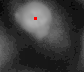
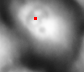
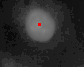
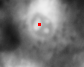
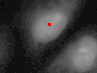
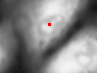

In [ ]:
frame = CytoDataFrame(
    data=sample_dir / "BR00117006_shrunken.parquet",
    data_context_dir=str(sample_dir / "images/orig"),
    data_outline_context_dir=(
        str(sample_dir / "images/outlines") if outlines.value else None
    ),
    display_options={
        "brightness": brightness.value,
        "composite_channels": (
            {"OrigDNA": "cyan", "OrigRNA": "magenta"} if composite.value else None
        ),
    },
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][: row_count.value]
table_html = frame._repr_html_(debug=True)
image_viewer = make_dataframe(frame, table_html)
mo.vstack(
    [
        mo.md(f"Showing **{len(frame)} cells**, brightness **{brightness.value}**."),
        image_viewer,
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Nuclei_Texture_Variance_RNA_5_03_256,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,106.035972,,,
1,1,2,33.590487,,,
2,1,3,53.527363,,,

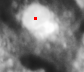
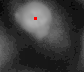
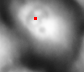
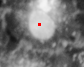
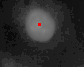
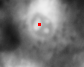
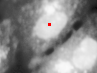
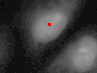
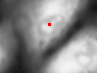

In [ ]:
_frame = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Nuclei_Texture_Variance_RNA_5_03_256",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
frame_02 = _frame
html_02 = render_frame(frame_02)
mo.vstack(
    [
        mo.md("## 1. JUMP image crops\n\nview JUMP plate BR00117006 with images"),
        make_dataframe(frame_02, html_02),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,,,
1,1,2,,,
2,1,3,,,

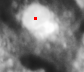
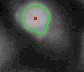
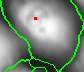
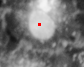
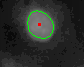
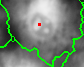
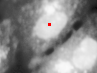
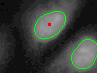
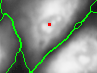

In [ ]:
_frame = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    data_outline_context_dir=f"{jump_data_path}/images/outlines",
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
frame_03 = _frame
html_03 = render_frame(frame_03)
mo.vstack(
    [
        mo.md(
            """
        ## 2. JUMP segmentation outlines

        view JUMP plate BR00117006 with images and overlaid outlines for
        segmentation
        """
        ),
        make_dataframe(frame_03, html_03),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,,,
1,1,2,,,
2,1,3,,,

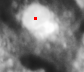
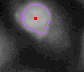
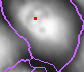
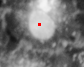
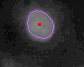
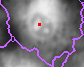
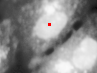
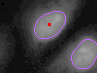
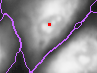

In [ ]:
frame_04 = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    data_outline_context_dir=f"{jump_data_path}/images/outlines",
    display_options={"outline_color": (200, 100, 255)},
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
html_04 = render_frame(frame_04)
mo.vstack(
    [
        mo.md(
            """
        ## 3. Custom outline color

        view JUMP plate BR00117006 with images and overlaid outlines for
        segmentation and changing the color to something besides the default
        (default is green).
        """
        ),
        make_dataframe(frame_04, html_04),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,,,
1,1,2,,,
2,1,3,,,

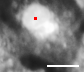
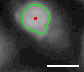
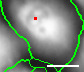
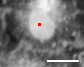
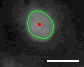
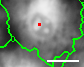
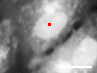
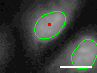
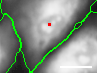

In [ ]:
frame_05 = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    data_outline_context_dir=f"{jump_data_path}/images/outlines",
    display_options={
        "um_per_pixel": 0.155,
        "scale_bar": {
            "length_um": 5,
            "location": "lower right",
            "color": (255, 255, 255),
            "thickness_px": 2,
            "margin_px": 5,
        },
    },
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
html_05 = render_frame(frame_05)
mo.vstack(
    [
        mo.md(
            """
        ## 4. Calibrated scale bars

        view JUMP plate BR00117006 with images and overlaid outlines for
        segmentation and adding scale bars which show how micrometers scale to
        the pixels displayed.
        """
        ),
        make_dataframe(frame_05, html_05),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigDNA,Image_FileName_OrigRNA,Image_Composite
0,1,1,,,
1,1,2,,,
2,1,3,,,

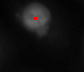
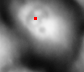
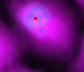
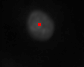
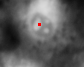
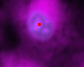
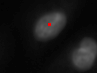
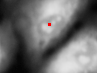
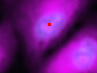

In [ ]:
frame_06 = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    display_options={
        "composite_channels": {"OrigDNA": "cyan", "OrigRNA": "#ff00ff"},
        "equalize_clip_limit": 0.01,
    },
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
html_06 = render_frame(frame_06)
mo.vstack(
    [
        mo.md(
            """
        ## 5. DNA/RNA composite

        view JUMP plate BR00117006 and merge multiple channels into a single
        single-cell crop composite (similar to a Fiji composite). Each channel
        is tinted a color and additively blended so colocalization is easy to
        see. Here we combine the nucleus (DNA) with the cell-segmentation
        channel (RNA for JUMP) using cyan/magenta, which read more clearly
        than red/green/blue where channels overlap. Channels may be named by
        their column, their channel suffix (e.g. "OrigDNA"), or a substring,
        and colors may be a name, a hex code, or an (r, g, b) tuple. The
        merged image is added as a new "Image_Composite" column and a small
        color legend is shown with the table. "equalize_clip_limit" is an easy
        contrast knob: a small value gives a milder, less over-saturated
        result.
        """
        ),
        make_dataframe(frame_06, html_06),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigDNA,Image_FileName_OrigRNA,Image_Composite
0,1,1,,,
1,1,2,,,
2,1,3,,,

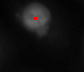
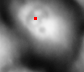
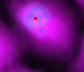
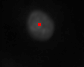
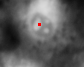
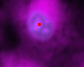
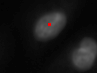
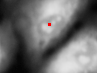
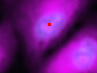

In [ ]:
frame_07 = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    display_options={"composite_channels": "all", "equalize_clip_limit": 0.01},
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
html_07 = render_frame(frame_07)
mo.vstack(
    [
        mo.md(
            """
        ## 6. Automatic channel composite

        the same composite feature can merge *all* image channels at once by
        passing "all", using default cyan/magenta/yellow (CMY) colors. The
        color legend shown with the table indicates which channel each color
        represents.
        """
        ),
        make_dataframe(frame_07, html_07),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigDNA,Image_FileName_OrigRNA,Image_Composite
0,1,1,,,
1,1,2,,,
2,1,3,,,

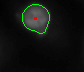
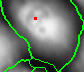
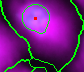
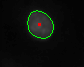
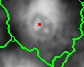
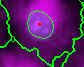
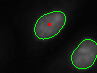
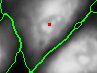
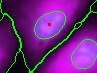

In [ ]:
frame_08 = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    data_outline_context_dir=f"{jump_data_path}/images/outlines",
    display_options={
        "composite_channels": {"OrigDNA": "cyan", "OrigRNA": "magenta"},
        "equalize_clip_limit": 0.01,
    },
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
html_08 = render_frame(frame_08)
mo.vstack(
    [
        mo.md(
            """
        ## 7. Composite with outlines

        composites also keep the segmentation outline and red center dot when
        those are configured, so a single merged view still shows where each
        object was segmented. Here we merge channels and overlay outlines from
        the segmentation directory (cyan/magenta channels keep the green
        outline easy to distinguish).
        """
        ),
        make_dataframe(frame_08, html_08),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,,,
1,1,2,,,
2,1,3,,,

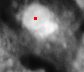
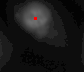
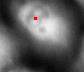
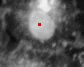
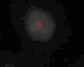
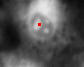
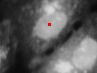
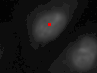
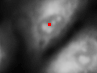

In [ ]:
frame_09 = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    display_options={"brightness": 10},
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
html_09 = render_frame(frame_09)
mo.vstack(
    [
        mo.md(
            """
        ## 8. Brightness adjustment

        view JUMP plate BR00117006 with images and adjust the brightness
        """
        ),
        make_dataframe(frame_09, html_09),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,,,
1,1,2,,,
2,1,3,,,

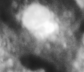
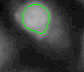
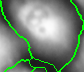
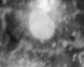
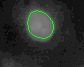
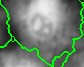
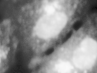
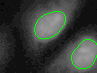
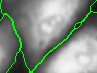

In [ ]:
frame_10 = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    data_outline_context_dir=f"{jump_data_path}/images/outlines",
    display_options={"center_dot": False},
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
html_10 = render_frame(frame_10)
mo.vstack(
    [
        mo.md(
            """
        ## 9. Hide the center dot

        view JUMP plate BR00117006 with images and overlaid outlines for
        segmentation and removing the optional red center dot.
        """
        ),
        make_dataframe(frame_10, html_10),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,,,
1,1,2,,,
2,1,3,,,

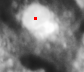
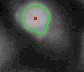
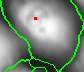
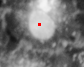
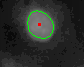
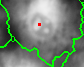
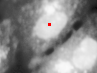
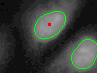
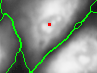

In [ ]:
frame_11 = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    data_outline_context_dir=f"{jump_data_path}/images/outlines",
    display_options={"width": "100"},
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
html_11 = render_frame(frame_11)
mo.vstack(
    [
        mo.md(
            """
        ## 10. Image width

        view JUMP plate BR00117006 with images and change the display width
        """
        ),
        make_dataframe(frame_11, html_11),
    ]
)

,0,1,2,3,4
Metadata_ImageNumber,1,1,1,1,1
Cells_Number_Object_Number,1,2,3,4,5
Image_FileName_OrigAGP,,,,,
Image_FileName_OrigDNA,,,,,
Image_FileName_OrigRNA,,,,,

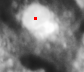
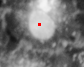
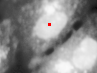
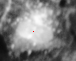
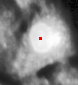
...
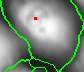
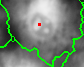
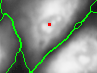
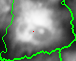
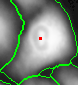

In [ ]:
frame_12 = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    data_outline_context_dir=f"{jump_data_path}/images/outlines",
    display_options={"width": "200px", "height": "auto"},
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:5].T
html_12 = render_frame(frame_12)
mo.vstack(
    [
        mo.md(
            """
        ## 11. Transpose and image dimensions

        view JUMP plate BR00117006 with images, change the display height and
        width and also transpose for a different view of things.
        """
        ),
        make_dataframe(frame_12, html_12),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA,Image_FileName_OrigAGP_OMEArrow_ORIG,Image_FileName_OrigAGP_OMEArrow_LABL,Image_FileName_OrigAGP_OMEArrow_COMP,Image_FileName_OrigDNA_OMEArrow_ORIG,Image_FileName_OrigDNA_OMEArrow_LABL,Image_FileName_OrigDNA_OMEArrow_COMP,Image_FileName_OrigRNA_OMEArrow_ORIG,Image_FileName_OrigRNA_OMEArrow_LABL,Image_FileName_OrigRNA_OMEArrow_COMP
0,1,1,r01c01f01p01-ch2sk1fk1fl1.tiff,r01c01f01p01-ch5sk1fk1fl1.tiff,r01c01f01p01-ch3sk1fk1fl1.tiff,,None,,,,,,,
1,1,2,r01c01f01p01-ch2sk1fk1fl1.tiff,r01c01f01p01-ch5sk1fk1fl1.tiff,r01c01f01p01-ch3sk1fk1fl1.tiff,,None,,,,,,,
2,1,3,r01c01f01p01-ch2sk1fk1fl1.tiff,r01c01f01p01-ch5sk1fk1fl1.tiff,r01c01f01p01-ch3sk1fk1fl1.tiff,,None,,,,,,,

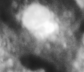
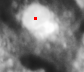
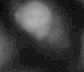
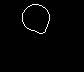
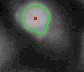
...
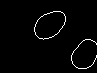
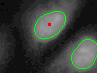
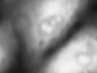
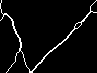
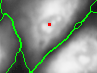

In [ ]:
with TemporaryDirectory() as _directory:
    _path = pathlib.Path(_directory) / "example.ome.parquet"
    frame_03.to_ome_parquet(file_path=str(_path))
    frame_13 = CytoDataFrame(data=_path)
html_13 = render_frame(frame_13)
mo.vstack(
    [
        mo.md(
            """
        ## 12. JUMP OME Parquet round trip

        export to OME Parquet, a format which uses OME Arrow to store OME-spec
        images as values within the table.
        """
        ),
        make_dataframe(frame_13, html_13),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,,,
1,1,2,,,
2,1,3,,,
3,1,4,,,
4,1,5,,,

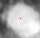
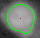
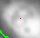
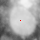
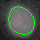
...
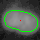
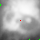
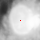
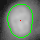
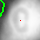

In [ ]:
frame_14 = CytoDataFrame(
    data=f"{jump_data_path}/BR00117006_shrunken.parquet",
    data_context_dir=f"{jump_data_path}/images/orig",
    data_outline_context_dir=f"{jump_data_path}/images/outlines",
    display_options={
        "offset_bounding_box": {
            "x_min": -20,
            "y_min": -20,
            "x_max": 20,
            "y_max": 20,
        }
    },
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:5]
html_14 = render_frame(frame_14)
mo.vstack(
    [
        mo.md(
            """
        ## 13. Bounding-box offsets

        view JUMP plate BR00117006 with images, changing the bounding box
        using offsets so each image has roughly the same size.
        """
        ),
        make_dataframe(frame_14, html_14),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,,,
1,1,2,,,
2,1,3,,,
3,1,4,,,
4,1,5,,,

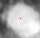
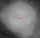
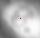
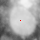
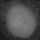
...
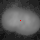
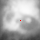
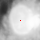
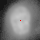
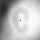

In [ ]:
_jump_without_bounding_boxes = pd.read_parquet(
    f"{jump_data_path}/BR00117006_shrunken.parquet"
)
_jump_without_bounding_boxes = _jump_without_bounding_boxes.drop(
    columns=[
        column
        for column in _jump_without_bounding_boxes.columns
        if "BoundingBox" in column
    ]
)
frame_15 = CytoDataFrame(
    data=_jump_without_bounding_boxes,
    data_context_dir=f"{jump_data_path}/images/orig",
    display_options={
        "offset_bounding_box": {
            "x_min": -20,
            "y_min": -20,
            "x_max": 20,
            "y_max": 20,
        }
    },
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:5]
html_15 = render_frame(frame_15)
mo.vstack(
    [
        mo.md(
            """
        ## 14. Crops without bounding-box columns

        CytoDataFrame can also crop images when the data does not include
        AreaShape bounding box columns (e.g. older CellProfiler outputs such
        as LINCS). Here we drop the bounding box columns to simulate this
        case; cropping then relies on offset_bounding_box applied to the
        compartment center coordinates.
        """
        ),
        make_dataframe(frame_15, html_15),
    ]
)

,Metadata_ImageNumber,Cells_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigRNA
0,1,1,,,
1,1,2,,,
2,1,3,,,

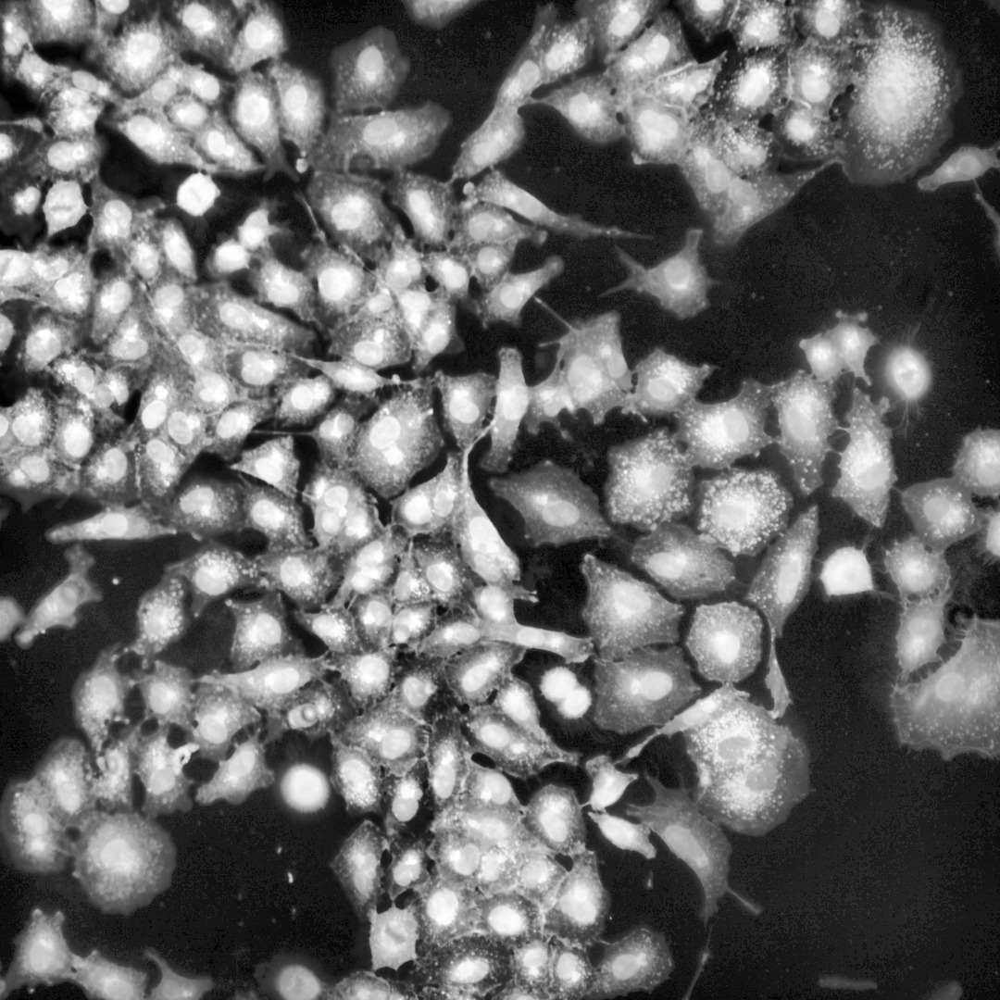
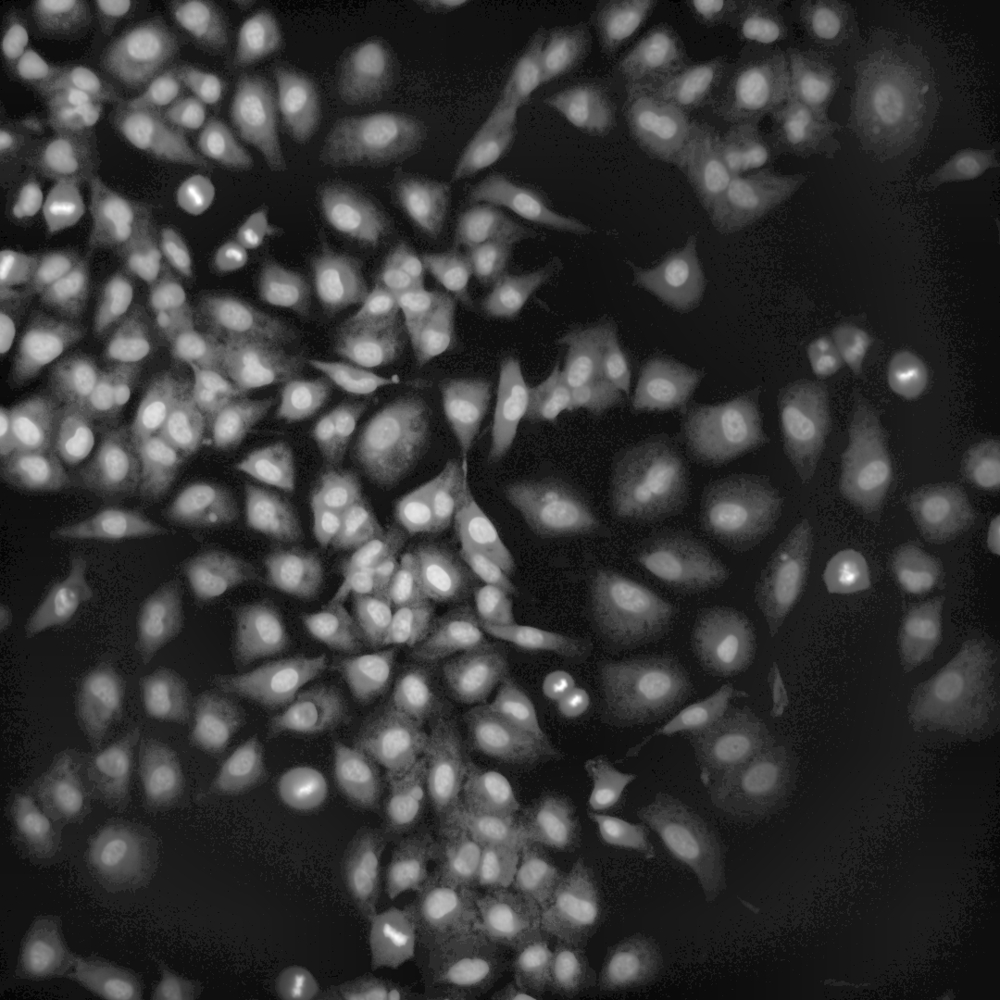
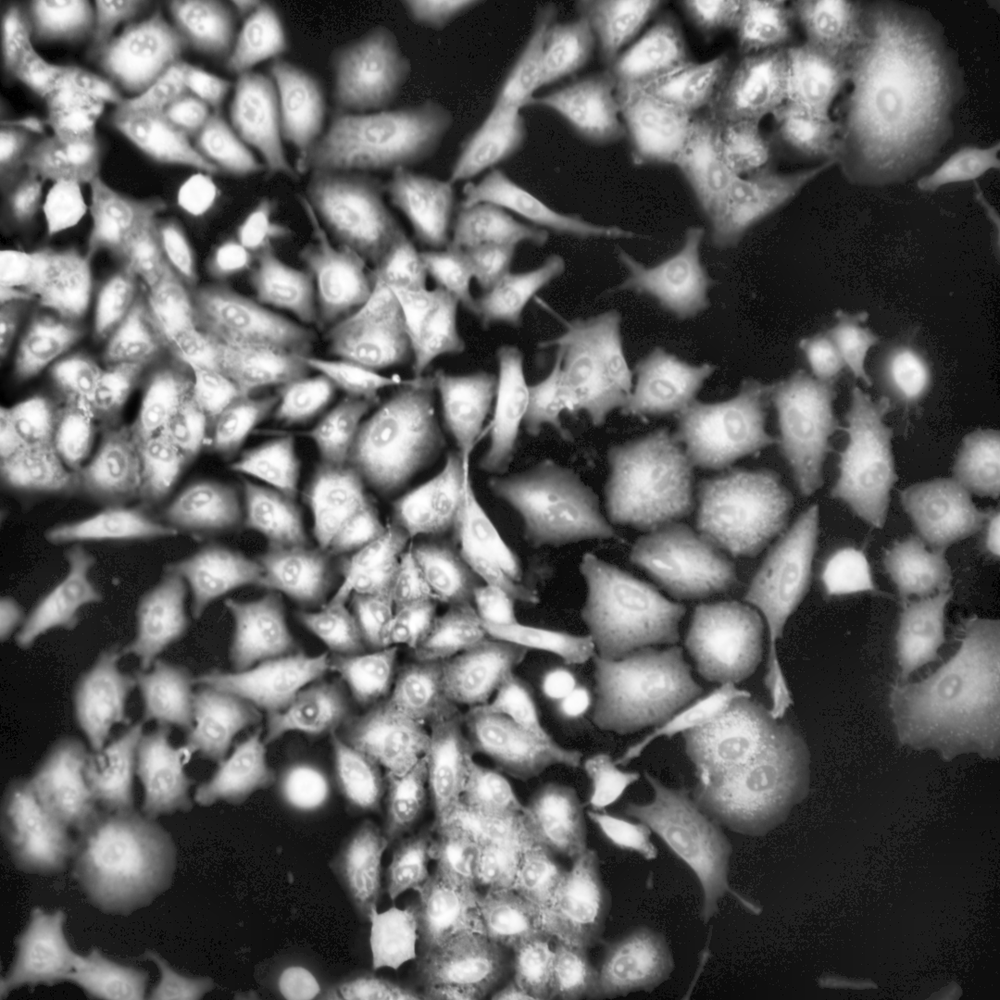
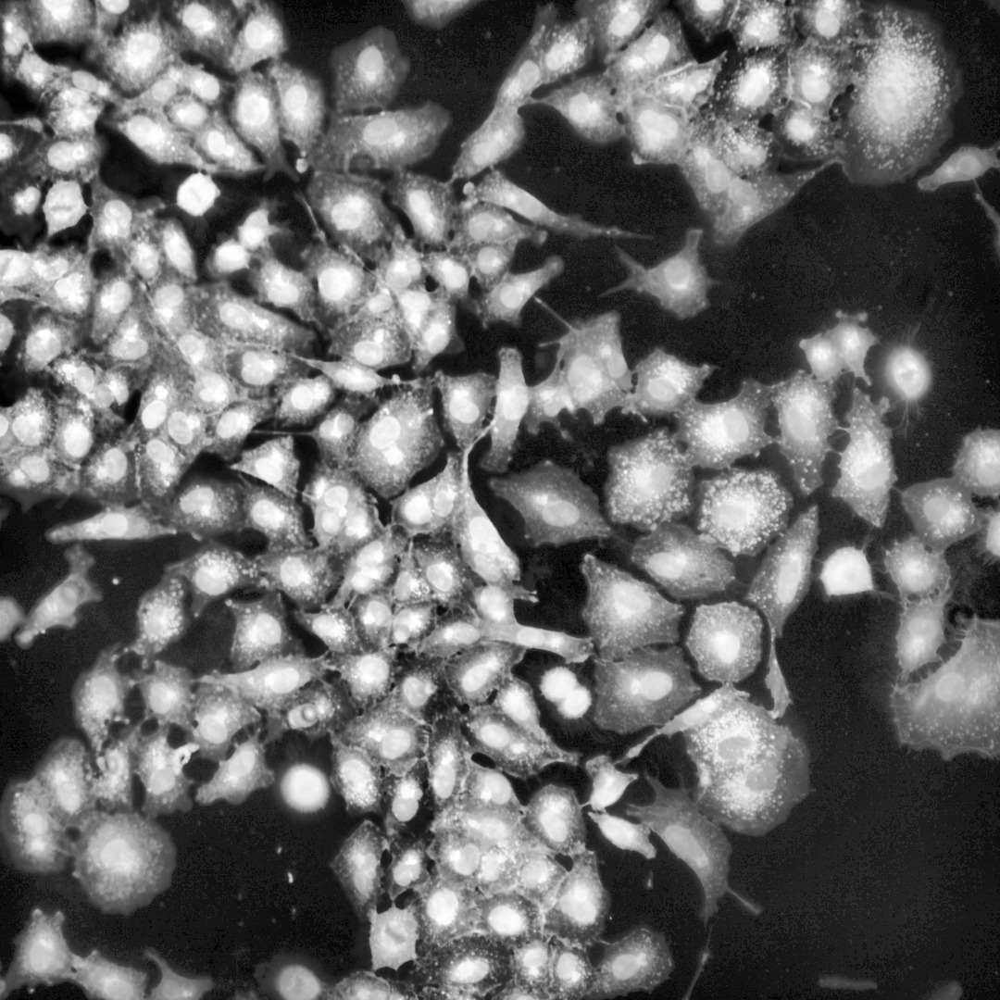
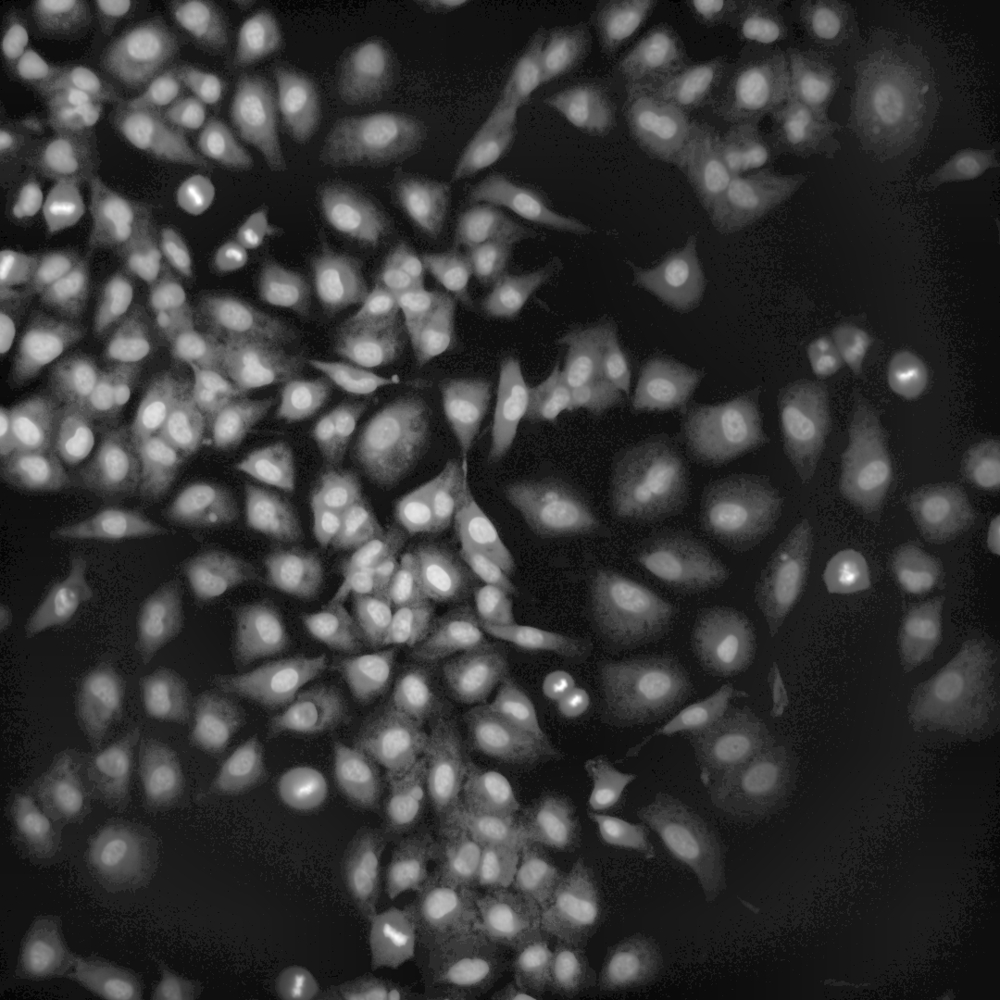
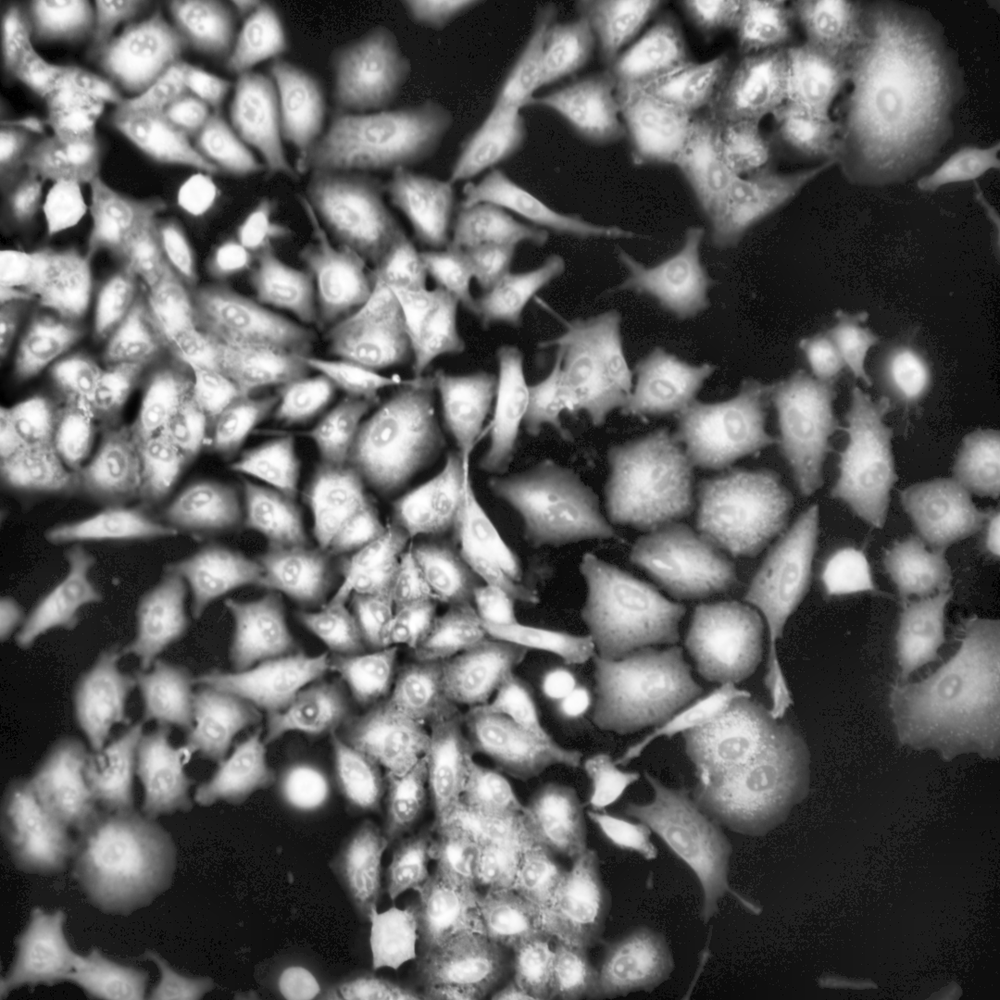
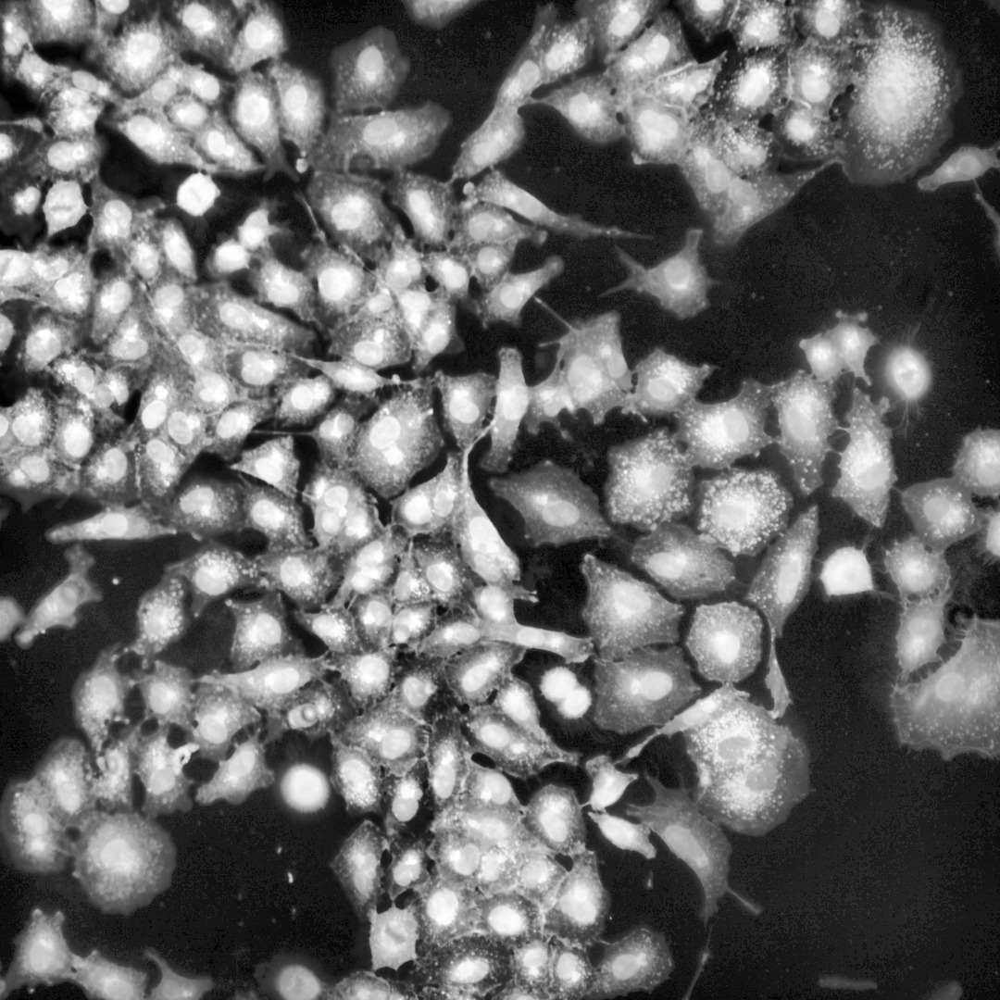
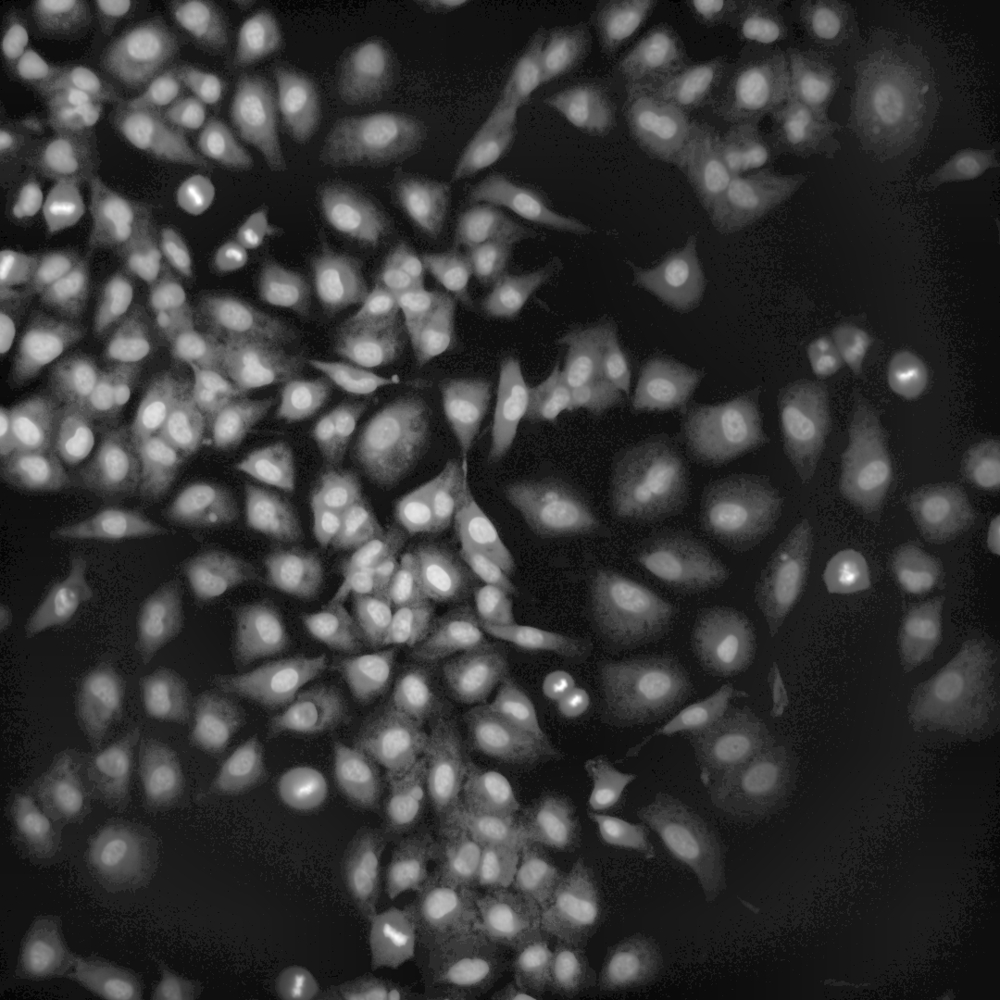
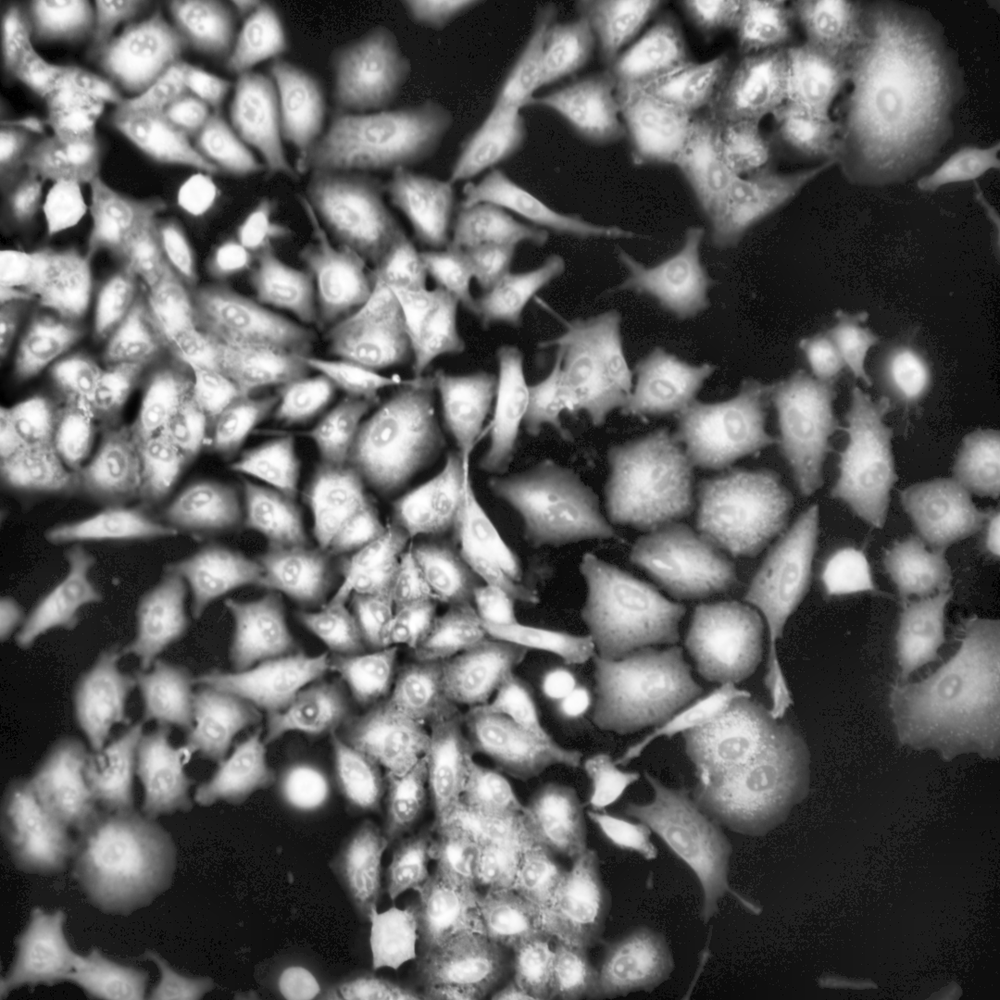

In [ ]:
_jump_image_level = pd.read_parquet(f"{jump_data_path}/BR00117006_shrunken.parquet")
_jump_image_level = _jump_image_level.drop(
    columns=[
        column
        for column in _jump_image_level.columns
        if "BoundingBox" in column or "Location_Center" in column
    ]
)
frame_16 = CytoDataFrame(
    data=_jump_image_level,
    data_context_dir=f"{jump_data_path}/images/orig",
    display_options={"render_whole_image": True},
)[
    [
        "Metadata_ImageNumber",
        "Cells_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
        "Image_FileName_OrigRNA",
    ]
][:3]
html_16 = render_frame(frame_16)
mo.vstack(
    [
        mo.md(
            """
        ## 15. Whole-image rendering

        For image-level data that has neither bounding box nor compartment
        center columns (for example, whole-image quality control metrics), use
        render_whole_image to display the full field of view without cropping.
        """
        ),
        make_dataframe(frame_16, html_16),
    ]
)

,Metadata_ImageNumber,Metadata_Cells_Number_Object_Number,Image_FileName_GFP,Image_FileName_RFP,Image_FileName_DAPI
353,31,4,,,
1564,113,17,,,
1275,94,5,,,

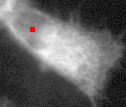
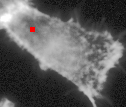
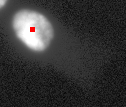
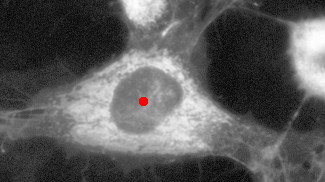
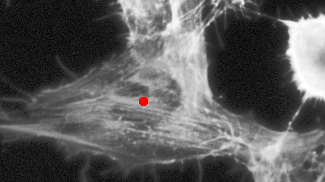
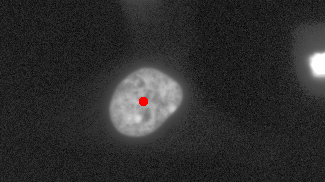
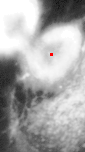
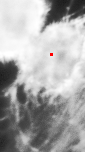
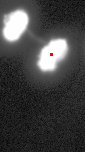

In [ ]:
frame_17 = CytoDataFrame(
    data=f"{nf1_cellpainting_path}/Plate_2_with_image_data_shrunken.parquet",
    data_context_dir=f"{nf1_cellpainting_path}/Plate_2_images",
)[
    [
        "Metadata_ImageNumber",
        "Metadata_Cells_Number_Object_Number",
        "Image_FileName_GFP",
        "Image_FileName_RFP",
        "Image_FileName_DAPI",
    ]
][:3]
html_17 = render_frame(frame_17)
mo.vstack(
    [
        mo.md("## 16. NF1 Cell Painting\n\nview NF1 Cell Painting data with images"),
        make_dataframe(frame_17, html_17),
    ]
)

,Metadata_ImageNumber,Metadata_Cells_Number_Object_Number,Image_FileName_GFP,Image_FileName_RFP,Image_FileName_DAPI
353,31,4,,,
1564,113,17,,,
1275,94,5,,,

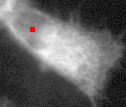
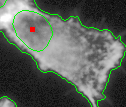
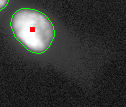
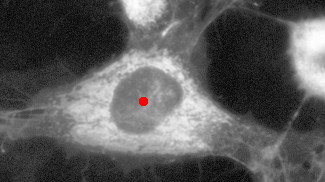
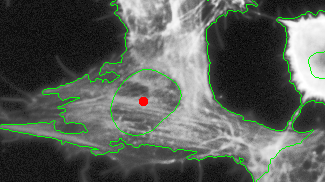
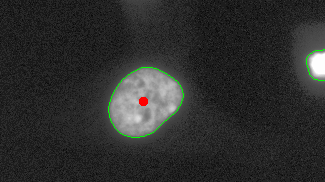
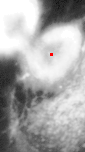
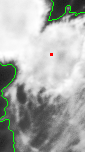
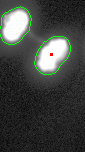

In [ ]:
_frame = CytoDataFrame(
    data=f"{nf1_cellpainting_path}/Plate_2_with_image_data_shrunken.parquet",
    data_context_dir=f"{nf1_cellpainting_path}/Plate_2_images",
    data_mask_context_dir=f"{nf1_cellpainting_path}/Plate_2_masks",
)[
    [
        "Metadata_ImageNumber",
        "Metadata_Cells_Number_Object_Number",
        "Image_FileName_GFP",
        "Image_FileName_RFP",
        "Image_FileName_DAPI",
    ]
][:3]
frame_18 = _frame
html_18 = render_frame(frame_18)
mo.vstack(
    [
        mo.md(
            """
        ## 17. NF1 segmentation masks

        view NF1 Cell Painting data with images and overlaid outlines from
        masks
        """
        ),
        make_dataframe(frame_18, html_18),
    ]
)

,Metadata_ImageNumber,Metadata_Cells_Number_Object_Number,Image_FileName_GFP,Image_FileName_RFP,Image_FileName_DAPI
353,31,4,,,
1564,113,17,,,
1275,94,5,,,

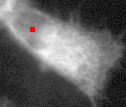
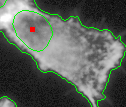
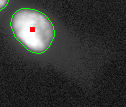
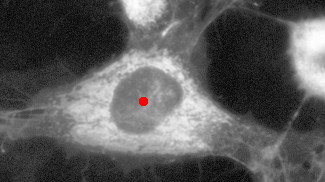
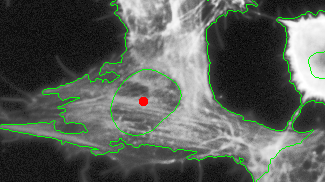
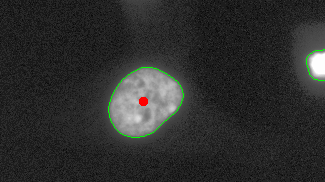
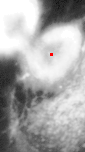
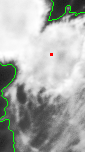
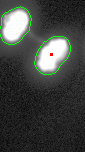

In [ ]:
_parquet_path = f"{nf1_cellpainting_path}/Plate_2_with_image_data_shrunken.parquet"
_nf1_dataset_with_modified_image_paths = pd.read_parquet(path=_parquet_path)
_nf1_dataset_with_modified_image_paths.loc[
    :, ["Image_PathName_DAPI", "Image_PathName_GFP", "Image_PathName_RFP"]
] = f"{pathlib.Path(_parquet_path).parent}/Plate_2_images"
frame_19 = CytoDataFrame(
    data=_nf1_dataset_with_modified_image_paths,
    data_mask_context_dir=f"{nf1_cellpainting_path}/Plate_2_masks",
)[
    [
        "Metadata_ImageNumber",
        "Metadata_Cells_Number_Object_Number",
        "Image_FileName_GFP",
        "Image_FileName_RFP",
        "Image_FileName_DAPI",
    ]
][:3]
html_19 = render_frame(frame_19)
mo.vstack(
    [
        mo.md(
            """
        ## 18. NF1 paths in a pandas DataFrame

        add active paths on the local system to show how CytoDataFrame may be
        used without specifying a context directory for images. Note: normally
        these paths are local to the system where the profile data was
        generated, which often is not the same as the system which will be
        used to analyze the data.
        """
        ),
        make_dataframe(frame_19, html_19),
    ]
)

,Metadata_ImageNumber,Metadata_Cells_Number_Object_Number,Image_FileName_GFP,Image_FileName_RFP,Image_FileName_DAPI,Image_FileName_GFP_OMEArrow_ORIG,Image_FileName_GFP_OMEArrow_LABL,Image_FileName_GFP_OMEArrow_COMP,Image_FileName_RFP_OMEArrow_ORIG,Image_FileName_RFP_OMEArrow_LABL,Image_FileName_RFP_OMEArrow_COMP,Image_FileName_DAPI_OMEArrow_ORIG,Image_FileName_DAPI_OMEArrow_LABL,Image_FileName_DAPI_OMEArrow_COMP
353,31,4,B7_01_2_3_GFP_001.tif,B7_01_3_3_RFP_001.tif,B7_01_1_3_DAPI_001.tif,,None,,,,,,,
1564,113,17,H12_01_2_1_GFP_001.tif,H12_01_3_1_RFP_001.tif,H12_01_1_1_DAPI_001.tif,,None,,,,,,,
1275,94,5,F7_01_2_2_GFP_001.tif,F7_01_3_2_RFP_001.tif,F7_01_1_2_DAPI_001.tif,,None,,,,,,,

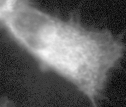
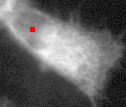
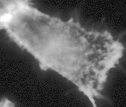
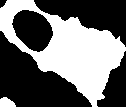
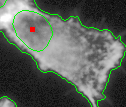
...
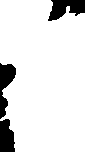
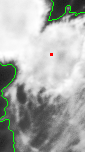
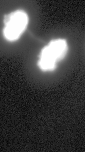
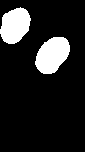
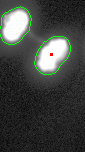

In [ ]:
with TemporaryDirectory() as _directory:
    _path = pathlib.Path(_directory) / "example.ome.parquet"
    frame_18.to_ome_parquet(file_path=str(_path))
    frame_20 = CytoDataFrame(data=_path)
html_20 = render_frame(frame_20)
mo.vstack(
    [
        mo.md(
            """
        ## 19. NF1 OME Parquet round trip

        export to OME Parquet, a format which uses OME Arrow to store OME-spec
        images as values within the table.
        """
        ),
        make_dataframe(frame_20, html_20),
    ]
)

,Metadata_ImageNumber,Nuclei_Number_Object_Number,Image_FileName_A647,Image_FileName_DAPI,Image_FileName_GOLD
0,1,1,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
1,1,2,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
2,1,3,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff

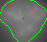
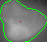

In [ ]:
frame_21 = CytoDataFrame(
    data=f"{nuclear_speckles_path}/test_slide1_converted.parquet",
    data_context_dir=f"{nuclear_speckles_path}/images/plate1",
    data_mask_context_dir=f"{nuclear_speckles_path}/masks/plate1",
)[
    [
        "Metadata_ImageNumber",
        "Nuclei_Number_Object_Number",
        "Image_FileName_A647",
        "Image_FileName_DAPI",
        "Image_FileName_GOLD",
    ]
][:3]
html_21 = render_frame(frame_21)
mo.vstack(
    [
        mo.md(
            """
        ## 20. Nuclear speckles with masks

        view nuclear speckles data with images and overlaid outlines from
        masks
        """
        ),
        make_dataframe(frame_21, html_21),
    ]
)

,Metadata_ImageNumber,Nuclei_Number_Object_Number,Nuclei_Texture_Variance_DAPI_3_03_256,Image_FileName_A647,Image_FileName_DAPI,Image_FileName_GOLD
0,1,1,2.484139,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
1,1,2,12.026326,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
2,1,3,51.418746,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
3,1,4,47.049561,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
4,1,5,117.135912,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
5,1,6,25.371580,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
6,1,7,23.930735,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
7,1,8,2.973642,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
8,1,9,8.355843,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
9,1,10,150.652194,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff

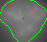
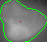
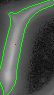
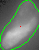
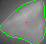
...
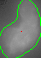
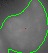
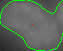
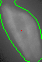
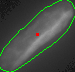

In [ ]:
frame_22 = CytoDataFrame(
    data=f"{nuclear_speckles_path}/test_slide1_converted.parquet",
    data_context_dir=f"{nuclear_speckles_path}/images/plate1",
    data_mask_context_dir=f"{nuclear_speckles_path}/masks/plate1",
    display_options={"filter_columns": ["Nuclei_Texture_Variance_DAPI_3_03_256"]},
)[
    [
        "Metadata_ImageNumber",
        "Nuclei_Number_Object_Number",
        "Nuclei_Texture_Variance_DAPI_3_03_256",
        "Image_FileName_A647",
        "Image_FileName_DAPI",
        "Image_FileName_GOLD",
    ]
]
html_22 = render_frame(frame_22)
mo.vstack(
    [
        mo.md(
            """
        ## 21. Filter nuclear speckles by texture

        view nuclear speckles data with images and overlaid outlines from
        masks and also apply a filter to only show rows where the value for
        "Nuclei_Texture_Variance_DAPI_3_03_256".
        """
        ),
        make_dataframe(frame_22, html_22),
    ]
)

In [ ]:
_values = frame_22["Nuclei_Texture_Variance_DAPI_3_03_256"]
texture_range = mo.ui.range_slider(
    start=float(_values.min()),
    stop=float(_values.max()),
    step=float((_values.max() - _values.min()) / 100),
    value=(float(_values.min()), float(_values.max())),
    label="DAPI texture variance range",
    show_value=True,
)
texture_range

&lt;marimo-range-slider data-initial-value=&#x27;[0.43224888492436264,150.65219447832595]&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eDAPI texture variance range&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-start=&#x27;0.43224888492436264&#x27; data-stop=&#x27;150.65219447832595&#x27; data-step=&#x27;1.5021994559340157&#x27; data-steps=&#x27;[]&#x27; data-debounce=&#x27;false&#x27; data-orientation=&#x27;&amp;quot;horizontal&amp;quot;&#x27; data-show-value=&#x27;true&#x27; data-full-width=&#x27;false&#x27; data-disabled=&#x27;false&#x27;&gt;&lt;/marimo-range-slider&gt;

,Metadata_ImageNumber,Nuclei_Number_Object_Number,Nuclei_Texture_Variance_DAPI_3_03_256,Image_FileName_A647,Image_FileName_DAPI,Image_FileName_GOLD
0,1,1,2.484139,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
1,1,2,12.026326,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
2,1,3,51.418746,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
3,1,4,47.049561,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
4,1,5,117.135912,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
5,1,6,25.371580,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
6,1,7,23.930735,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
7,1,8,2.973642,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
8,1,9,8.355843,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff
9,1,10,150.652194,slide1_A1_M10_CH1_Z09_illumcorrect.tiff,,slide1_A1_M10_CH2_Z09_illumcorrect.tiff

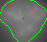
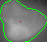
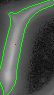
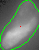
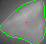
...
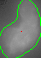
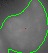
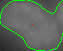
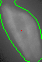
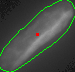

In [ ]:
_lower, _upper = texture_range.value
filtered_frame = frame_22[
    frame_22["Nuclei_Texture_Variance_DAPI_3_03_256"].between(_lower, _upper)
]
filtered_html = render_frame(filtered_frame)
mo.vstack(
    [
        mo.md(
            f"Filtered nuclear speckles: **{len(filtered_frame)} / "
            f"{len(frame_22)} cells**"
        ),
        make_dataframe(filtered_frame, filtered_html),
    ]
)

,Metadata_ImageNumber,Metadata_Nuclei_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA
0,3,3,,
1,3,4,,
2,3,6,,
3,3,7,,
4,3,8,,

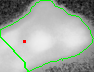
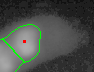
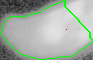
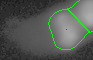
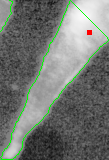
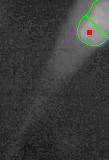
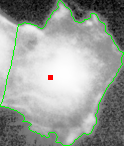
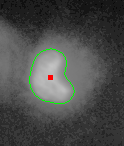
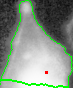
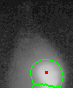

In [ ]:
_cdf = CytoDataFrame(
    data=f"{pediatric_cancer_atlas_path}/BR00143976_shrunken.parquet",
    data_context_dir=f"{pediatric_cancer_atlas_path}/images/orig",
    data_outline_context_dir=f"{pediatric_cancer_atlas_path}/images/outlines",
    segmentation_file_regex={
        "CellsOutlines_BR(\\d+)_C(\\d{2})_\\d+\\.tiff": ".*ch3.*\\.tiff",
        "NucleiOutlines_BR(\\d+)_C(\\d{2})_\\d+\\.tiff": ".*ch5.*\\.tiff",
    },
)[
    [
        "Metadata_ImageNumber",
        "Metadata_Nuclei_Number_Object_Number",
        "Image_FileName_OrigAGP",
        "Image_FileName_OrigDNA",
    ]
]
frame_23 = _cdf
html_23 = render_frame(frame_23)
mo.vstack(
    [
        mo.md(
            """
        ## 22. Pediatric cancer atlas: segmentation regex

        view ALSF pediatric cancer atlas plate BR00143976 with images
        """
        ),
        make_dataframe(frame_23, html_23),
    ]
)

,Metadata_ImageNumber,Metadata_Nuclei_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA
0,3,3,,
1,3,4,,
2,3,6,,
3,3,7,,
4,3,8,,

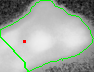
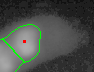
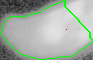
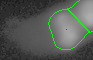
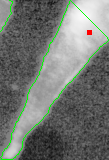
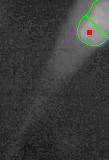
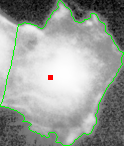
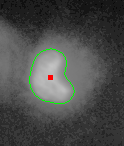
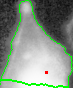
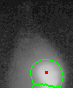

In [ ]:
frame_24 = frame_23
html_24 = render_frame(frame_24)
mo.vstack(
    [
        mo.md(
            """
        ## 23. Reuse the same CytoDataFrame

        show that we can use the cytodataframe again by quick variable
        reference.
        """
        ),
        make_dataframe(frame_24, html_24),
    ]
)

,Metadata_ImageNumber,Metadata_Nuclei_Number_Object_Number,Image_FileName_OrigAGP,Image_FileName_OrigDNA,Image_FileName_OrigAGP_OMEArrow_ORIG,Image_FileName_OrigAGP_OMEArrow_LABL,Image_FileName_OrigAGP_OMEArrow_COMP,Image_FileName_OrigDNA_OMEArrow_ORIG,Image_FileName_OrigDNA_OMEArrow_LABL,Image_FileName_OrigDNA_OMEArrow_COMP
0,3,3,r03c03f03p01-ch3sk1fk1fl1.tiff,r03c03f03p01-ch5sk1fk1fl1.tiff,,,,,,
1,3,4,r03c03f03p01-ch3sk1fk1fl1.tiff,r03c03f03p01-ch5sk1fk1fl1.tiff,,,,,,
2,3,6,r03c03f03p01-ch3sk1fk1fl1.tiff,r03c03f03p01-ch5sk1fk1fl1.tiff,,,,,,
3,3,7,r03c03f03p01-ch3sk1fk1fl1.tiff,r03c03f03p01-ch5sk1fk1fl1.tiff,,,,,,
4,3,8,r03c03f03p01-ch3sk1fk1fl1.tiff,r03c03f03p01-ch5sk1fk1fl1.tiff,,,,,,

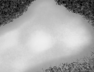
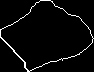
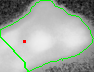
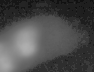
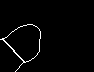
...
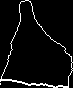
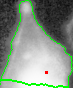
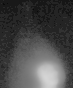
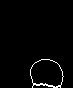
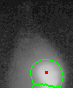

In [ ]:
with TemporaryDirectory() as _directory:
    _path = pathlib.Path(_directory) / "example.ome.parquet"
    frame_23.to_ome_parquet(file_path=str(_path))
    frame_25 = CytoDataFrame(data=_path)
html_25 = render_frame(frame_25)
mo.vstack(
    [
        mo.md(
            """
        ## 24. Pediatric cancer atlas OME Parquet round trip

        export to OME Parquet, a format which uses OME Arrow to store OME-spec
        images as values within the table.
        """
        ),
        make_dataframe(frame_25, html_25),
    ]
)

In [ ]:
import numpy as np

from cytodataframe.volume import build_3d_image_html_view


def make_3d_table(frame: CytoDataFrame, label_opacity: float = 0.35) -> object:
    """Render only the requested page's volumes in a native dataframe."""
    table = pd.DataFrame(frame).copy()
    format_mapping = {}
    for column in frame._find_3d_columns_for_display():
        preview = f"{column} preview"
        while preview in table.columns:
            preview += " preview"
        table.insert(
            table.columns.get_loc(column) + 1,
            preview,
            [str(row) for row in range(len(frame))],
        )

        def render_volume(position: str, column: str = column) -> object:
            row = frame.index[int(position)]
            volume, dims = frame._get_3d_volume_from_cell(row, column)
            labels = frame._get_3d_label_overlay_from_cell(
                row, column, expected_shape=volume.shape
            )
            # The browser renderer accepts uint8. Normalize instead of
            # truncating the uint16 fixture; use PyVista's percentile range.
            positive = volume[volume > 0]
            low, high = np.percentile(
                positive if positive.size else volume, (1.0, 99.9)
            )
            high = max(float(high), float(low) + 1.0)
            normalized = (
                np.clip((volume.astype(float) - low) / (high - low), 0, 1) * 255
            ).astype(np.uint8)
            document = build_3d_image_html_view(
                volume=normalized,
                dims=dims,
                data_value=str(frame.loc[row, column]),
                candidate_path=pathlib.Path(str(frame.loc[row, column])),
                display_options={
                    "width": "300px",
                    "height": "300px",
                    "label_overlay_opacity": label_opacity,
                    "volume_cmap": "gray",
                    "volume_background": "black",
                    "vtk_js_url": "https://unpkg.com/vtk.js@34.9.1/vtk.js",
                },
                label_volume=labels,
            )
            # Return the rich object so dataframe cells can render its MIME.
            return mo.iframe(document, width="320px", height="320px")

        format_mapping[preview] = render_volume
    return mo.ui.dataframe(
        table.reset_index(drop=True), format_mapping=format_mapping, page_size=3
    )


def show_volume_table(
    frame: CytoDataFrame, snapshot: str, opacity: float, static: bool
) -> object:
    if static:
        return make_dataframe(frame, snapshot)
    # VTK/Cocoa cannot create windows on marimo's worker thread. Only
    # the standalone export process may generate native PNG snapshots.
    return make_3d_table(frame, label_opacity=opacity)

In [ ]:
mo.output.append(
    mo.md("""
### Interactive 3D views

Drag a volume to rotate it; scroll to zoom. The live view uses CytoDataFrame's
vtk.js renderer in an iframe, with percentile-normalized uint8 intensities.
It requires access to the pinned vtk.js CDN. Masks are a single green binary
overlay, not PyVista's per-object colors; the live view does not reproduce
PyVista's center marker or all its toolbar options. Each masked image has
its own **Show mask** checkbox: toggling it preserves the camera and does
not affect the other images. Use the opacity slider to adjust mask opacity.
Static captures use the original PyVista renderer, including masks and
center markers.
""")
)
label_opacity = mo.ui.slider(
    0.0, 1.0, step=0.05, value=0.35, label="3D mask opacity", show_value=True
)
label_opacity

&lt;marimo-slider data-initial-value=&#x27;0.35&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003e3D mask opacity&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-start=&#x27;0.0&#x27; data-stop=&#x27;1.0&#x27; data-step=&#x27;0.05&#x27; data-steps=&#x27;[]&#x27; data-debounce=&#x27;false&#x27; data-disabled=&#x27;false&#x27; data-orientation=&#x27;&amp;quot;horizontal&amp;quot;&#x27; data-show-value=&#x27;true&#x27; data-include-input=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-slider&gt;

,ImageNumber,ObjectNumber,FileName_Nuclei
0,1,1,
1,1,2,
2,1,3,

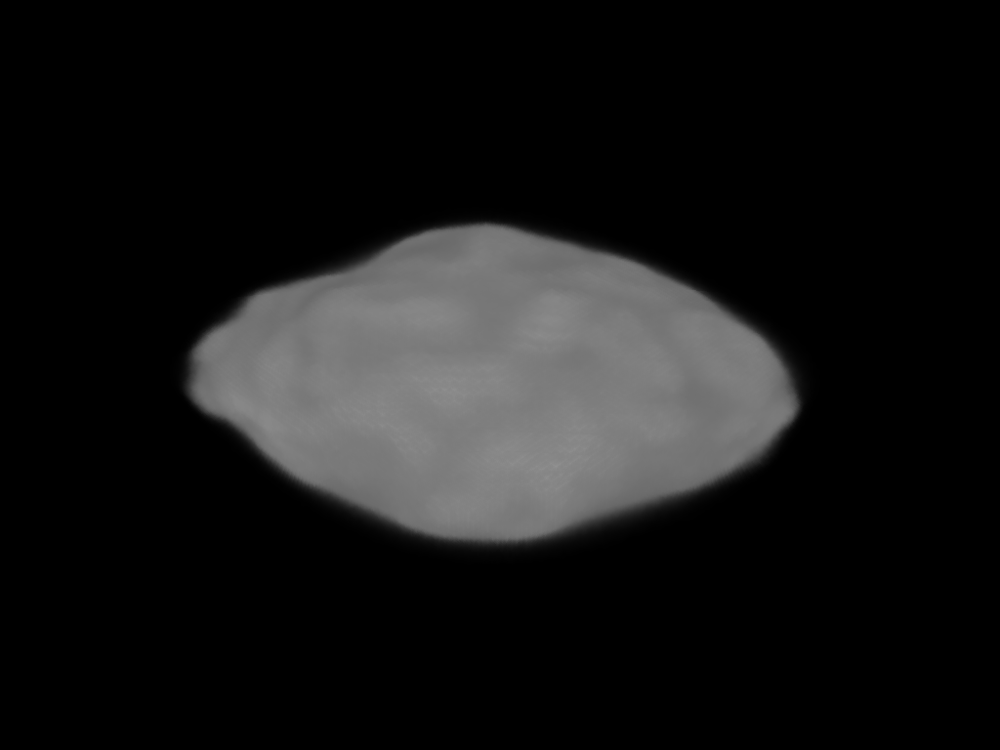
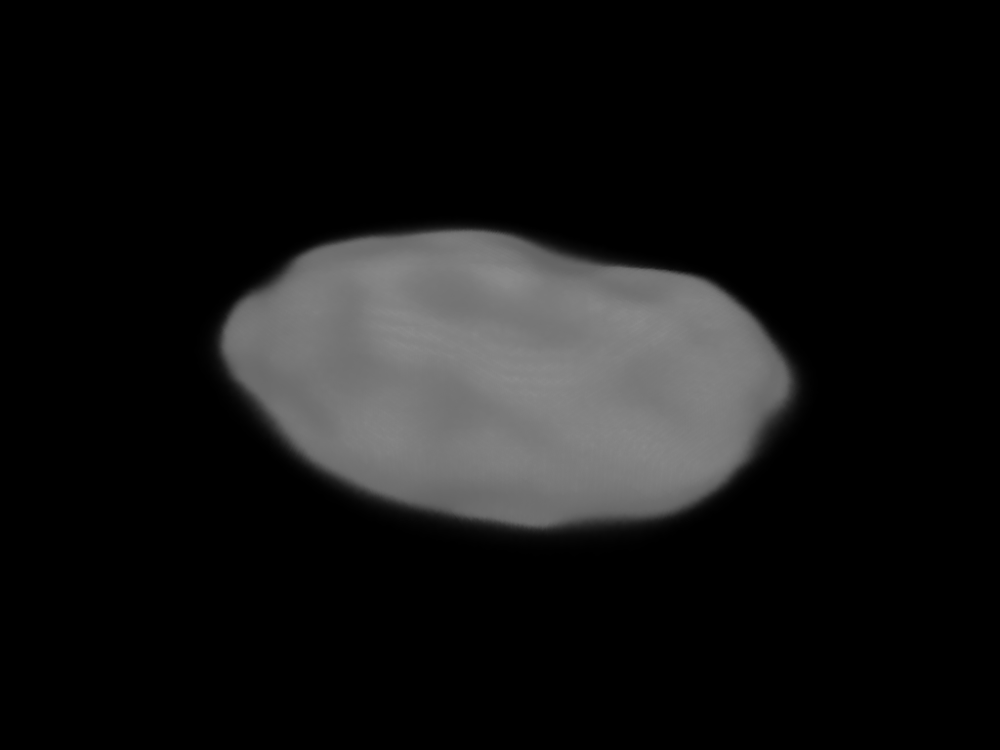
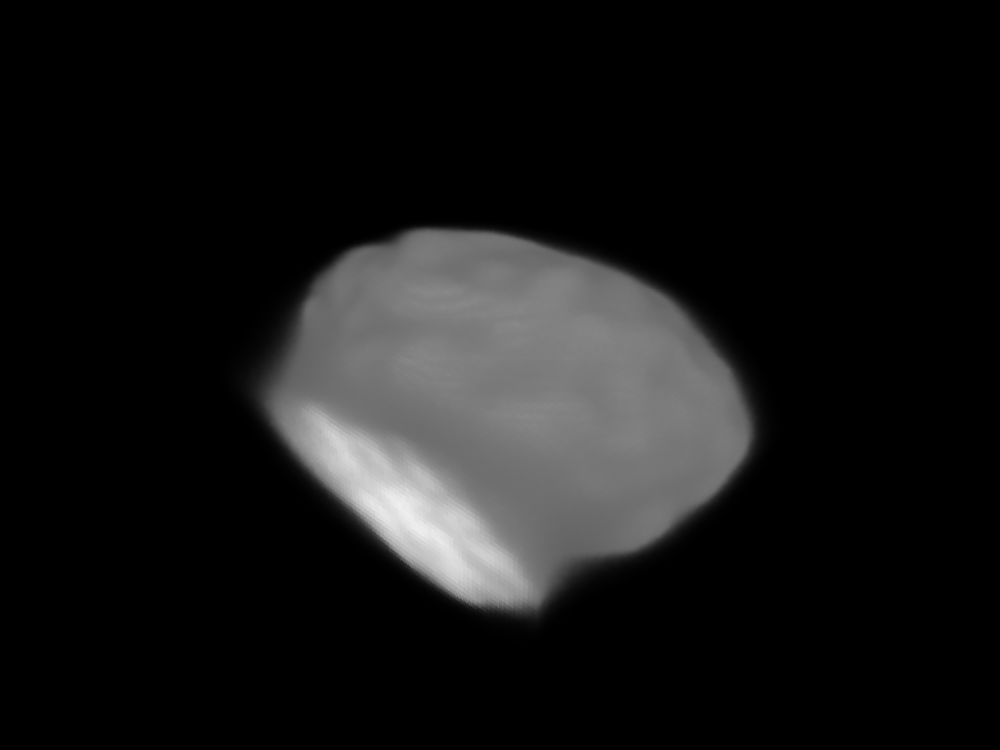

In [ ]:
_cdf = CytoDataFrame(
    data=pathlib.Path(cp_3d_path) / "output/MyExpt_RealsizeNuclei.csv",
    data_context_dir=str(pathlib.Path(cp_3d_path) / "input"),
)
frame_26 = _cdf[["ImageNumber", "ObjectNumber", "FileName_Nuclei"]][:3]
html_26 = render_frame(frame_26) if static_3d else ""
volume_viewer_26 = show_volume_table(frame_26, html_26, label_opacity.value, static_3d)
mo.vstack(
    [
        mo.md(
            """
        ## 25. 3D nuclei

        3D example dataset, showing how CytoDataFrame can be used with 3D data
        for visualization.
        """
        ),
        volume_viewer_26,
    ]
)

,ImageNumber,ObjectNumber,FileName_Nuclei
0,1,1,
1,1,2,
2,1,3,

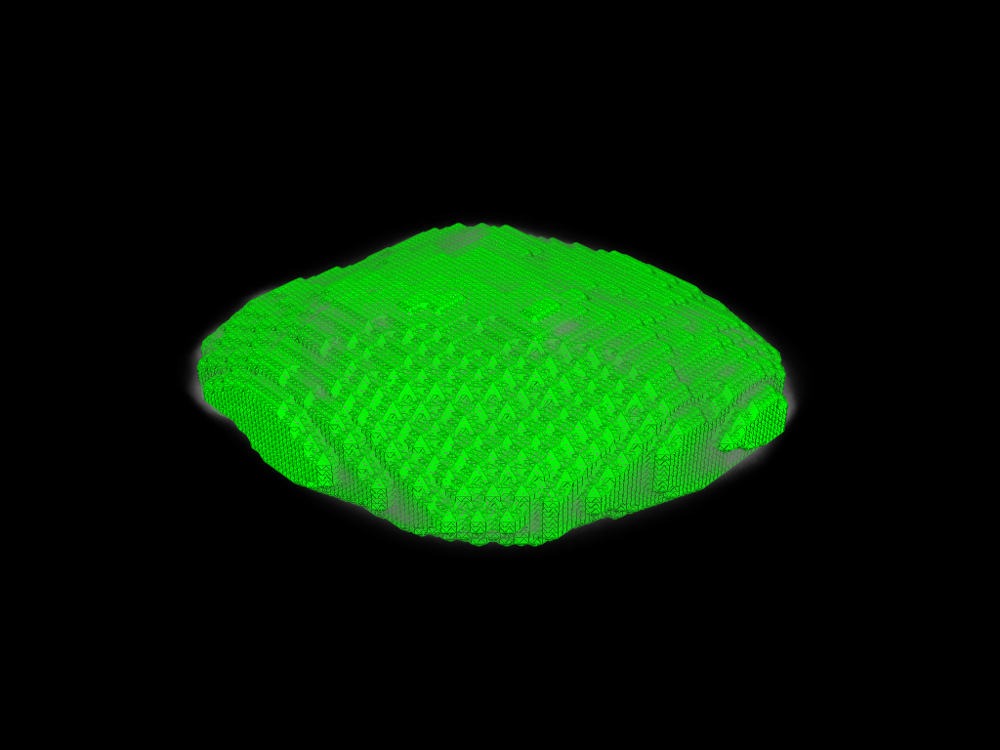
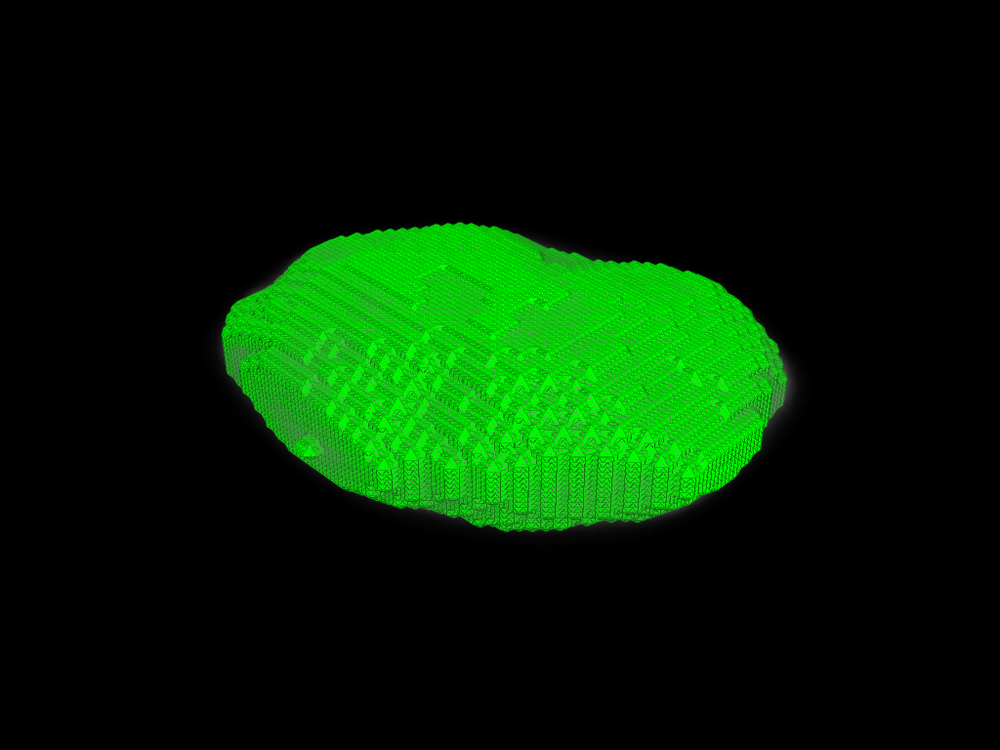
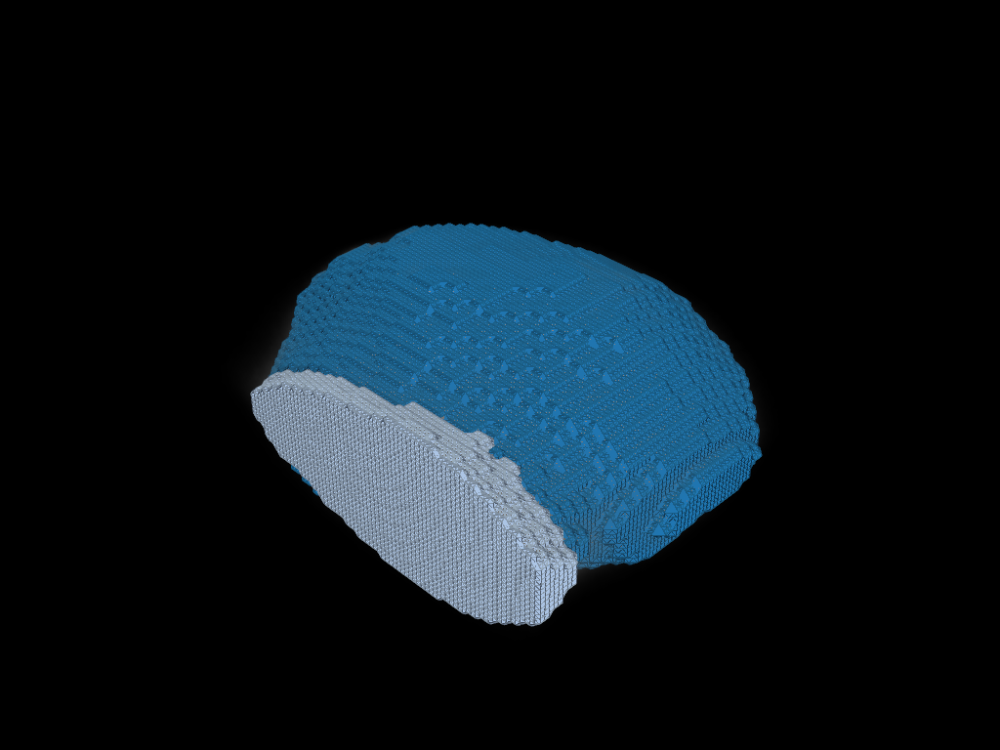

In [ ]:
_cdf = CytoDataFrame(
    data=pathlib.Path(cp_3d_path) / "output/MyExpt_RealsizeNuclei.csv",
    data_context_dir=str(pathlib.Path(cp_3d_path) / "input"),
    data_mask_context_dir=str(pathlib.Path(cp_3d_path) / "output/masks"),
)
frame_27 = _cdf[["ImageNumber", "ObjectNumber", "FileName_Nuclei"]][:3]
html_27 = render_frame(frame_27) if static_3d else ""
volume_viewer_27 = show_volume_table(frame_27, html_27, label_opacity.value, static_3d)
mo.vstack(
    [
        mo.md(
            """
        ## 26. 3D nuclei with segmentation masks

        read 3d images with segmentation masks and show the segmentation masks
        are also 3D.
        """
        ),
        volume_viewer_27,
    ]
)